In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [89]:
import tensorflow as tf

In [90]:
print("hola mundo")

hola mundo


In [91]:
args= dict(
    image_size= (48, 48),
    color_mode= 'grayscale',
    batch_size= 32)

In [92]:
train_ds= tf.keras.utils.image_dataset_from_directory(
    "archive(6)/train",
    **args)
vals_ds= tf.keras.utils.image_dataset_from_directory(
    "archive(6)/validation",
    **args)
test_ds= tf.keras.utils.image_dataset_from_directory(
    "archive(6)/test", shuffle= False, **args)

classes= train_ds.class_names
print(classes)

Found 28821 files belonging to 7 classes.
Found 7066 files belonging to 7 classes.
Found 3589 files belonging to 7 classes.
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [93]:
def escalar(imagen, etiqueta):
    imagen= tf.cast(imagen, tf.float32)/255
    return imagen, etiqueta

ESCALAMIENTO DE LOS DATOS

In [94]:
train_ds= train_ds.map(escalar)
test_ds= test_ds.map(escalar)
vals_ds= vals_ds.map(escalar)


In [95]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(48, 48, 1)),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(len(classes), activation='softmax')
])


In [ ]:
model.compile(optimizer= 'adam',
              loss= 'sparse_categorical_crossentropy', metrics= ['accuracy'])  #metricas de entrenamiento

model.fit(train_ds, epochs= 15, validation_data= vals_ds)  #metricas de validacion

Epoch 1/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.2788 - loss: 1.7517 - val_accuracy: 0.3855 - val_loss: 1.5809
Epoch 2/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 33s 30ms/step - accuracy: 0.4208 - loss: 1.4762 - val_accuracy: 0.4633 - val_loss: 1.3904
Epoch 3/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 41s 30ms/step - accuracy: 0.4834 - loss: 1.3349 - val_accuracy: 0.4942 - val_loss: 1.3210
Epoch 4/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5210 - loss: 1.2378

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(48, 48, 1)),

    # Aumento de datos
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),

    tf.keras.layers.Conv2D(32, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(len(classes), activation='softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                     restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                         patience=2, min_lr=1e-5)
]

model.fit(train_ds, epochs=40, validation_data=vals_ds, callbacks=callbacks)

Epoch 1/40
901/901 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - accuracy: 0.2464 - loss: 1.9147 - val_accuracy: 0.2583 - val_loss: 1.8403 - learning_rate: 0.0010
Epoch 2/40
901/901 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step - accuracy: 0.2486 - loss: 1.8293 - val_accuracy: 0.2583 - val_loss: 1.8185 - learning_rate: 0.0010
Epoch 3/40
901/901 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step - accuracy: 0.2486 - loss: 1.8170 - val_accuracy: 0.2583 - val_loss: 1.8121 - learning_rate: 0.0010
Epoch 4/40
901/901 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step - accuracy: 0.2486 - loss: 1.8129 - val_accuracy: 0.2583 - val_loss: 1.8099 - learning_rate: 0.0010
Epoch 5/40
901/901 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step - accuracy: 0.2486 - loss: 1.8115 - val_accuracy: 0.2583 - val_loss: 1.8093 - learning_rate: 0.0010
Epoch 6/40
901/901 ━━━━━━━━━━━━━━━━━━━━ 32s 35ms/step - accuracy: 0.2486 - loss: 1.8110 - val_accuracy: 0.2583 - val_loss: 1.8091 - learning_rate: 0.0010
Epoch 7/40
901/901 ━━━━━━━━━━━━━━━━━━━━ 33s 37ms/step - accuracy: 0.2486 - l

In [ ]:
loss, accuracy= model.evaluate(test_ds)  #metricas de prueba
print(loss)
print(accuracy)

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2449 - loss: 1.8405
1.8405115604400635
0.24491502344608307


In [ ]:
probabilidades= model.predict(test_ds)
pred= np.argmax(probabilidades, 1)
print(pred[:6])

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
[3 3 3 3 3 3]


In [ ]:
#obtenemos las etiquetas reales del set d epruebas

In [ ]:
real= np.concatenate([y.numpy() for _, y in test_ds])
#obtenemos las imagnes del set de pruebas
imagenes_test = np.concatenate([x.numpy() for x, _ in test_ds])
print(real[:6])

[0 0 0 0 0 0]


In [ ]:
#seleccionamos indices aleatorios de las imagenes de prueba

In [ ]:
inidices= np.random.choice(len(imagenes_test), 8, replace= False) #ahora seleccionamos 8 indices

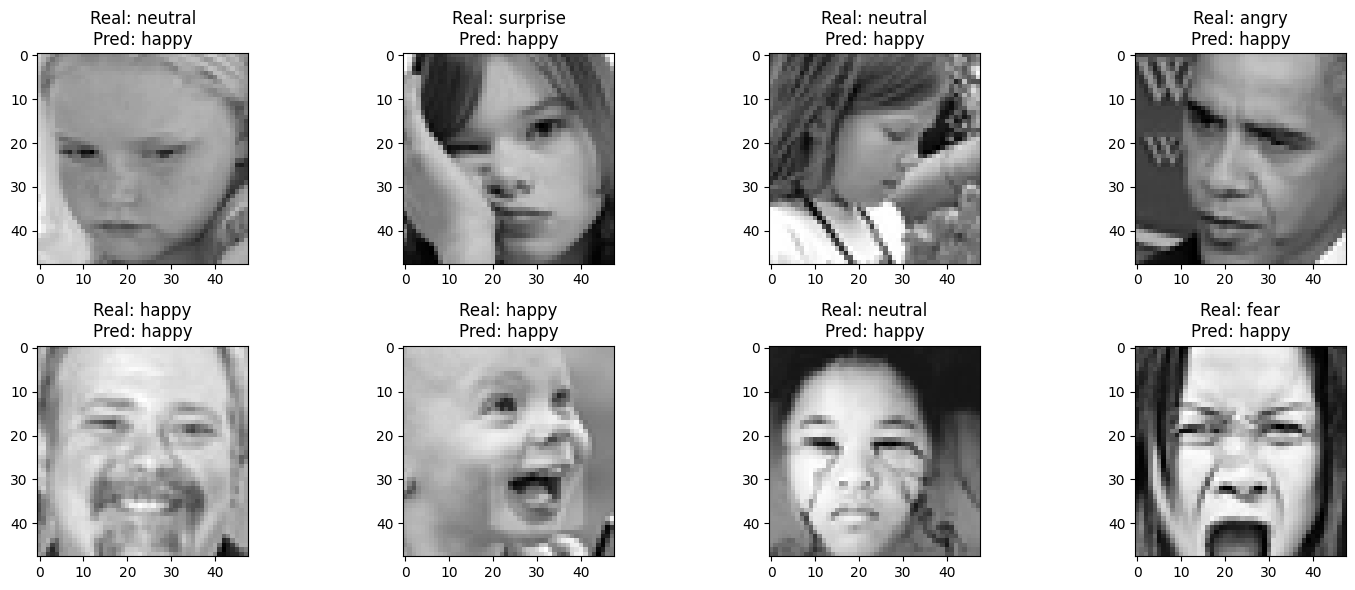

In [ ]:
plt.figure(figsize= (15, 6))
for i, indice in enumerate(inidices):
    plt.subplot(2, 4, i+1)
    plt.imshow(imagenes_test[indice].reshape(48, 48), cmap= 'gray')
    plt.title(f"Real: {classes[real[indice]]}\nPred: {classes[pred[indice]]}")
plt.tight_layout()
plt.show()